# Tutorial 13 (T13): Building Programs to Implement Decision Tree Algorithm

## 📌 Objective
Implement a **Decision Tree Classifier (CART)** on the agricultural crop recommendation dataset. Explore the bias-variance tradeoff by tuning `max_depth`, visualize tree decisions (`plot_tree`), compute Gini feature importances, and evaluate multi-class classification performance.

## 🔬 Key Concepts & Mathematical Formulas
- **Gini Impurity**: Measures the probability of misclassifying a randomly chosen element:
  $$G = 1 - \sum_{i=1}^C p_i^2$$
- **Information Gain (Entropy)**:
  $$H(S) = -\sum_{i=1}^C p_i \log_2(p_i)$$
  $$IG(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} H(S_v)$$
- **Mean Decrease in Impurity (MDI)**: Feature importance calculated by total reduction of Gini impurity brought by each feature across all tree splits.

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid", palette="muted")
print('Decision Tree libraries loaded!')

Decision Tree libraries loaded!


### Step 2: Load Data and Stratified Train-Test Split (80/20)

In [2]:
df = pd.read_csv('data/Crop_recommendation.csv')
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Training Set: {X_train.shape[0]} samples')
print(f'Testing Set:  {X_test.shape[0]} samples')

Training Set: 1760 samples
Testing Set:  440 samples


### Step 3: Hyperparameter Tuning - Tree Depth vs Overfitting
We vary `max_depth` from 1 to 12 and plot training vs testing accuracy to identify the sweet spot before overfitting begins.

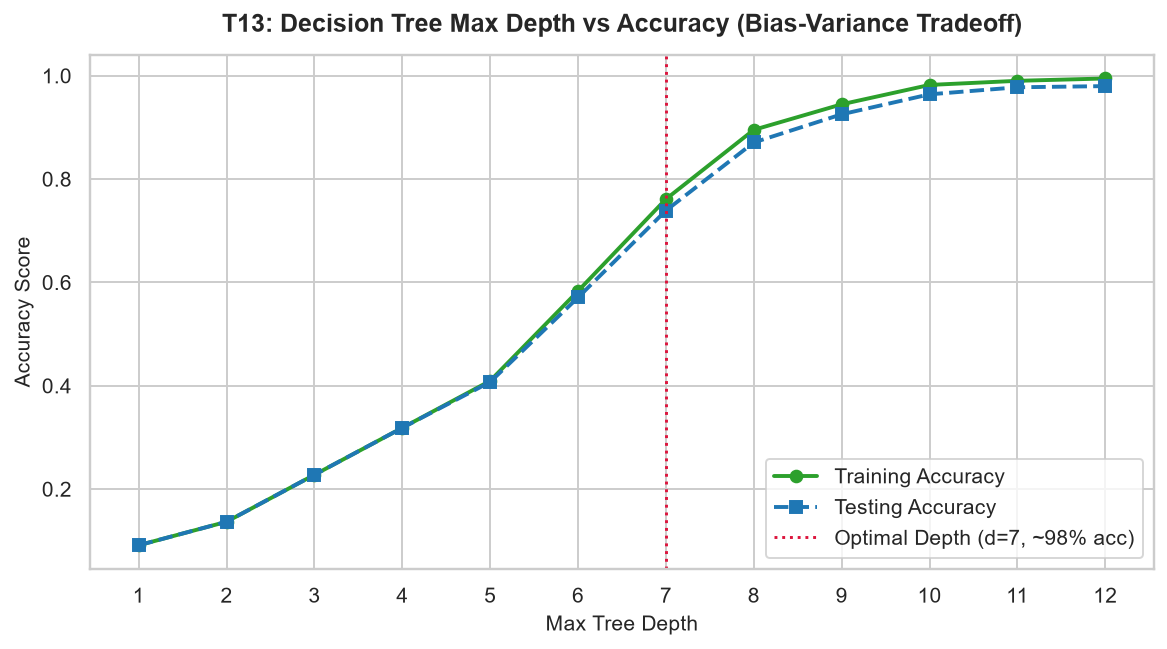

In [3]:
depths = range(1, 13)
train_accs = []
test_accs = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
    dt.fit(X_train, y_train)
    train_accs.append(dt.score(X_train, y_train))
    test_accs.append(dt.score(X_test, y_test))

plt.figure(figsize=(8.5, 4.8), dpi=140)
plt.plot(list(depths), train_accs, 'o-', label='Training Accuracy', color='#2ca02c', linewidth=2)
plt.plot(list(depths), test_accs, 's--', label='Testing Accuracy', color='#1f77b4', linewidth=2)
plt.title('T13: Decision Tree Max Depth vs Accuracy (Bias-Variance Tradeoff)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Max Tree Depth', fontsize=11)
plt.ylabel('Accuracy Score', fontsize=11)
plt.xticks(list(depths))
plt.axvline(x=7, color='crimson', linestyle=':', label='Optimal Depth (d=7, ~98% acc)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Step 4: Train Optimized Decision Tree ($d=7$)

In [4]:
best_dt = DecisionTreeClassifier(max_depth=7, criterion='gini', random_state=42)
best_dt.fit(X_train, y_train)
y_pred_dt = best_dt.predict(X_test)

train_acc = best_dt.score(X_train, y_train)
test_acc = accuracy_score(y_test, y_pred_dt)
print(f'Decision Tree Training Accuracy: {train_acc:.2%}')
print(f'Decision Tree Testing Accuracy:  {test_acc:.2%}')
print('\nClassification Report Summary:')
print(classification_report(y_test, y_pred_dt, digits=3))

Decision Tree Training Accuracy: 76.08%
Decision Tree Testing Accuracy:  73.86%

Classification Report Summary:
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      0.227     1.000     0.370        20
   blackgram      0.424     0.700     0.528        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      0.000     0.000     0.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.000     0.000     0.000        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      0.000     0.000     0.000        20
       maize      0.923     0.600     0.727        20
       mango      1.000     1.000     1.000        20
   mothbeans      0.731     0.950     0.826        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000

### Step 5: Confusion Matrix Heatmap

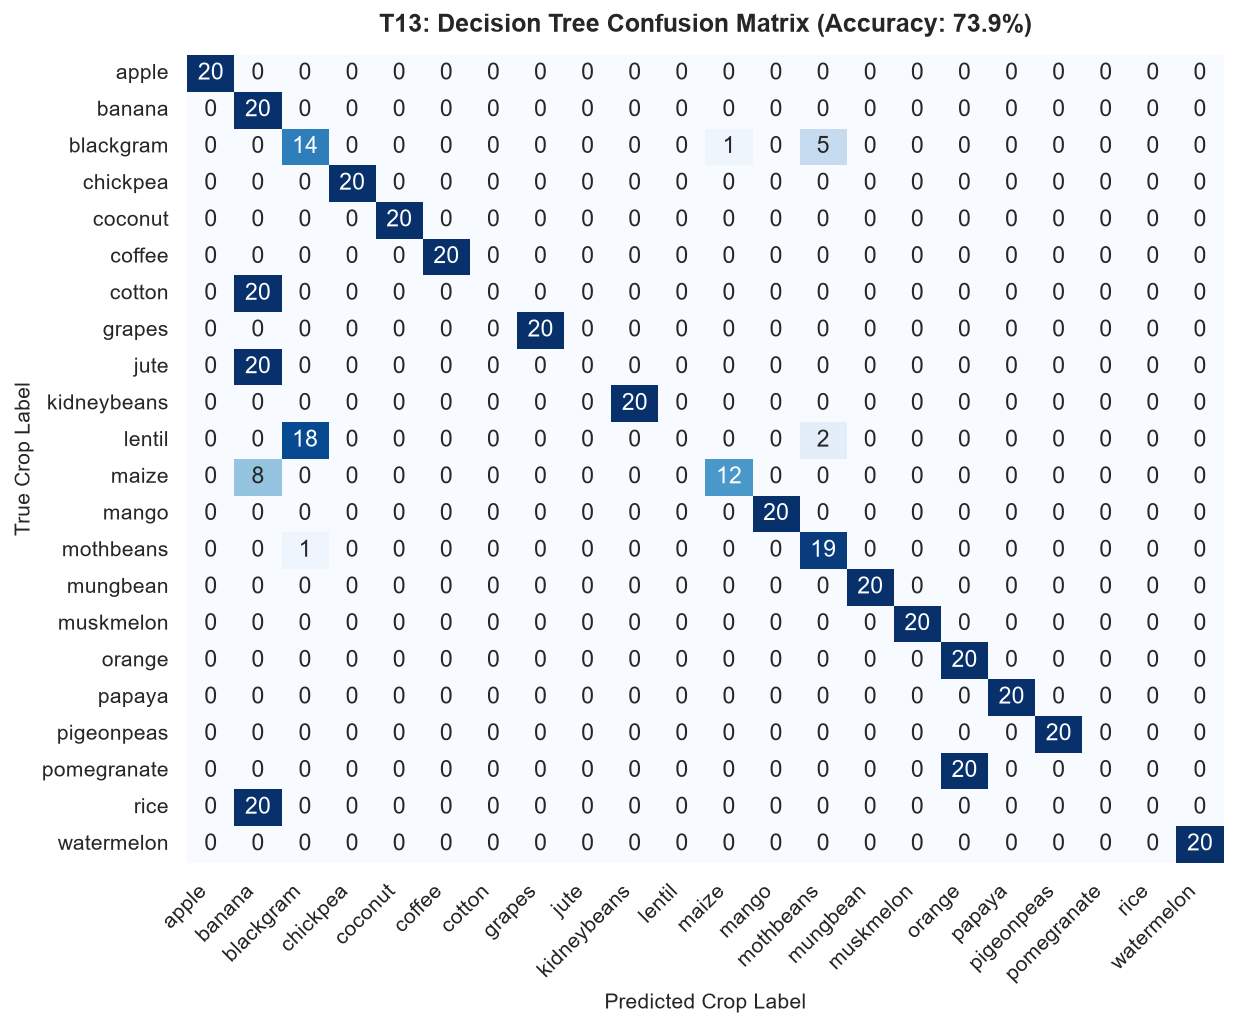

In [5]:
classes = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_dt, labels=classes)

plt.figure(figsize=(9, 7.5), dpi=140)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title(f'T13: Decision Tree Confusion Matrix (Accuracy: {test_acc:.1%})', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Crop Label', fontsize=11)
plt.ylabel('True Crop Label', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 6: Feature Importance Analysis (MDI)

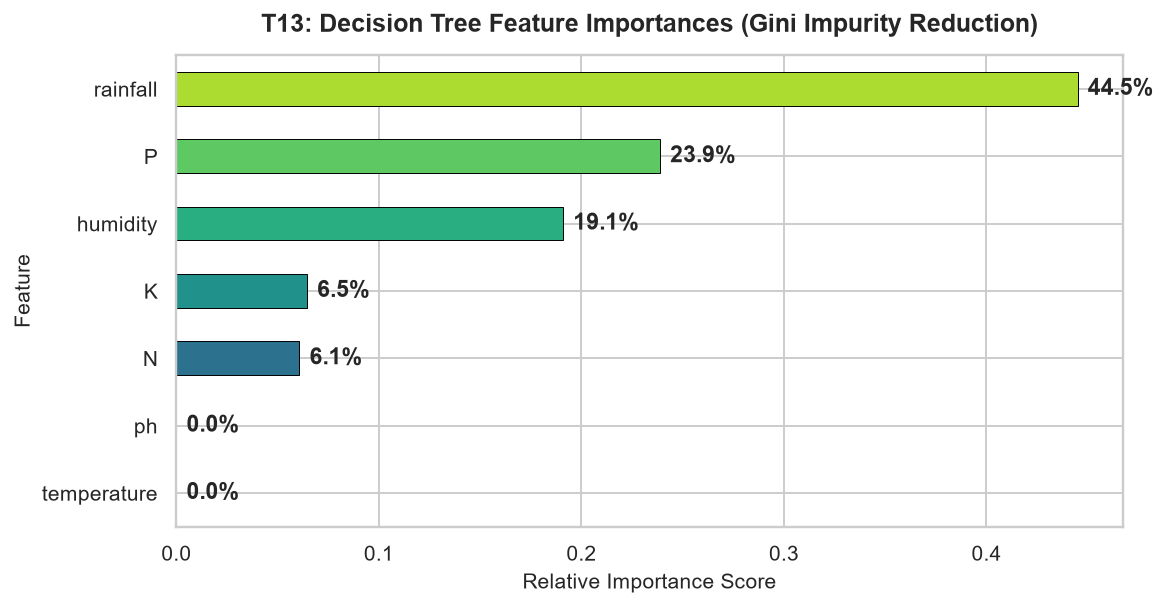

In [6]:
fi = pd.Series(best_dt.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8.5, 4.5), dpi=140)
colors = sns.color_palette('viridis', len(fi))
fi.plot(kind='barh', color=colors, edgecolor='black', linewidth=0.5)
plt.title('T13: Decision Tree Feature Importances (Gini Impurity Reduction)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Relative Importance Score', fontsize=11)
plt.ylabel('Feature', fontsize=11)
for idx, val in enumerate(fi):
    plt.text(val + 0.005, idx, f'{val:.1%}', va='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Step 7: Visualizing the Tree Structure

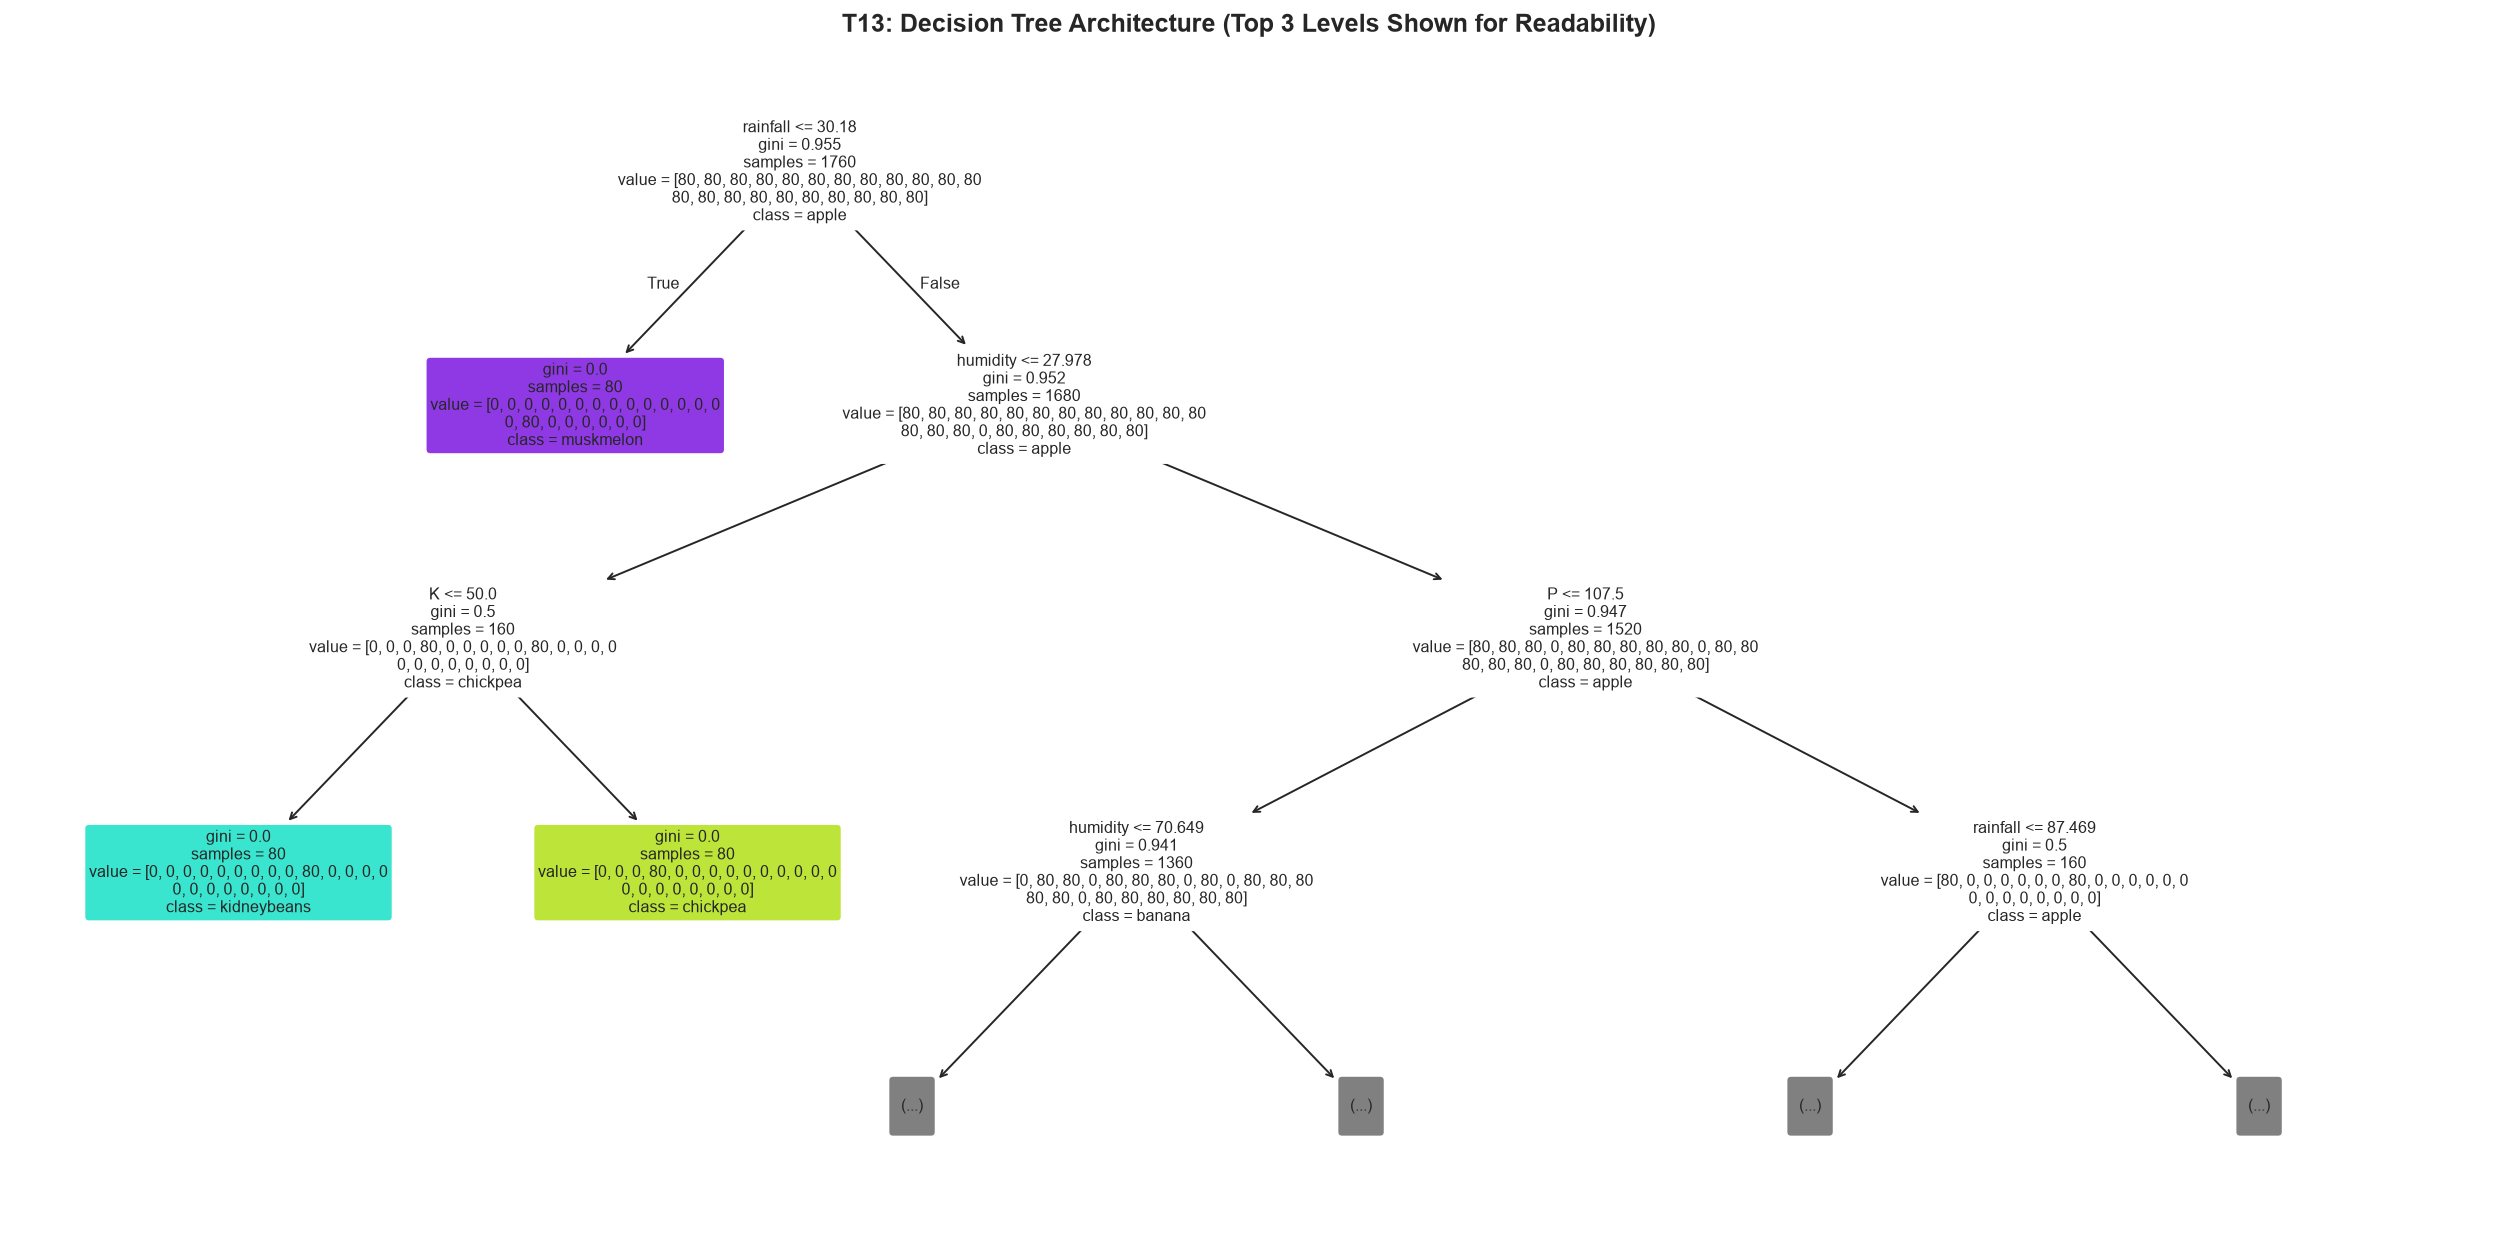

In [7]:
plt.figure(figsize=(18, 9), dpi=140)
plot_tree(best_dt, max_depth=3, feature_names=features, class_names=best_dt.classes_, filled=True, rounded=True, fontsize=8)
plt.title('T13: Decision Tree Architecture (Top 3 Levels Shown for Readability)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### 🎓 Viva Voce Questions & Answers (Tutorial 13)

1. **Q: How does CART choose the best split at each node?**
   - **A:** The CART algorithm evaluates every available feature and threshold, computing the weighted Gini impurity of the resulting subsets. It greedily selects the split that maximizes the Gini Impurity Reduction ($\Delta G = G_{\text{parent}} - \sum \frac{N_j}{N} G_{\text{child}_j}$).

2. **Q: What is tree pruning and why is it necessary?**
   - **A:** Without constraints, a decision tree will continue splitting until every leaf is pure ($G=0$), causing extreme overfitting. **Pre-pruning** stops tree growth early via `max_depth`, `min_samples_split`, or `min_samples_leaf`. **Post-pruning** (Cost-Complexity Pruning $\alpha$) grows the full tree and collapses branches with high complexity penalties.

3. **Q: How does Gini compare to Entropy?**
   - **A:** Both produce almost identical tree architectures. However, Gini impurity does not involve logarithmic computation ($\log_2$), making it computationally faster than Shannon Entropy.